# Signal, Image and Video: Detecting and Counting Blood Cells
Authors: Francesco Nesler, Francesco Di Bon

This notebook presents an automated image processing pipeline designed for the detection and enumeration of fundamental hematological components: Red Blood Cells (RBCs), White Blood Cells (WBCs), and Platelets.
This application is especially useful in hospitals' laboratories, enabling medical laboratory technicias to spot potentially problematic patients' conditions, such as:
- **Low RBC count (Anemia)**: May be caused by iron deficiency, internal bleeding, or bone marrow issues
- **High RBC count (Polycythemia)**: Might suggest dehydration or heart/lung diseases where the body is overcompensating for low oxygen levels
- **High WBC count**: Usually signals an infection or inflammation. However, extremely high counts can be a red flag for leukemia
- **Low WBC count**: Can indicate a weakened immune system, often due to viral infections, autoimmune disorders, or certain medications
- **High platelets count (Thrombocytosis)**: Can lead to dangerous blood clots, potentially causing strokes or heart attacks
- **Low platelets count (Thrombocytopenia)**: Puts a patient at risk for uncontrolled bleeding or easy bruising

Automating the analysis of microscopic blood images can drastically reduce the time required to perform such examinations.

## Technical Challenges

To ensure robust detection, the processing pipeline must overcome several constraints inherent to biomedical imaging, specifically:

- **Cell Overlapping (RBC Aggregation)**: Red Blood Cells frequently overlap or cluster together (rouleaux formation). In simple thresholding approaches, these clusters appear as a single large object rather than distinct entities, necessitating advanced segmentation techniques like the Watershed algorithm to separate touching cells.

- **Signal-to-Noise Ambiguity (Platelets)**: Platelets are significantly smaller than other cell types and possess irregular shapes. Due to their size, they are morphologically similar to background noise, dust, or staining artifacts, making the distinction between a valid platelet and image noise a critical challenge.

- **Variable Image Quality**: Biomedical slides often exhibit non-uniform illumination (vignetting) and soft, ill-defined cell boundaries. This lack of edge sharpness complicates the extraction of precise contours, requiring robust pre-processing steps such as contrast equalization (CLAHE) and Gaussian blurring to standardize the input data.

The workflow starts with the acquisition of a dataset containing the mentioned microscopic blood smear images along with bounding box annotations, which serve as the ground truth for the detection and localization of Red Blood Cells, White Blood Cells, and Platelets.

In [25]:

import os
import cv2
import glob
import json
import numpy as np
import matplotlib.pyplot as plt
import warnings

warnings.filterwarnings('ignore')
np.random.seed(42)

BASE_INPUT_DIR = 'bccd-blood-cell-count-and-detection-dataset'

DIRS = {
    'train': {
        'img': os.path.join(BASE_INPUT_DIR, 'train', 'img'),
        'ann': os.path.join(BASE_INPUT_DIR, 'train', 'ann')
    },
    'val': {
        'img': os.path.join(BASE_INPUT_DIR, 'val', 'img'),
        'ann': os.path.join(BASE_INPUT_DIR, 'val', 'ann')
    },
    'test': {
        'img': os.path.join(BASE_INPUT_DIR, 'test', 'img'),
        'ann': os.path.join(BASE_INPUT_DIR, 'test', 'ann')
    }
}


for split in ['train', 'val', 'test']:
    n_imgs = len(glob.glob(os.path.join(DIRS[split]['img'], '*.*')))
    n_anns = len(glob.glob(os.path.join(DIRS[split]['ann'], '*.json')))
    print(f"   - {split.upper()}: {n_imgs} images, {n_anns} json files")

   - TRAIN: 205 images, 205 json files
   - VAL: 87 images, 87 json files
   - TEST: 72 images, 72 json files


# Helper Functions
Visualization utilities andhelper functions used to keep our code clean.

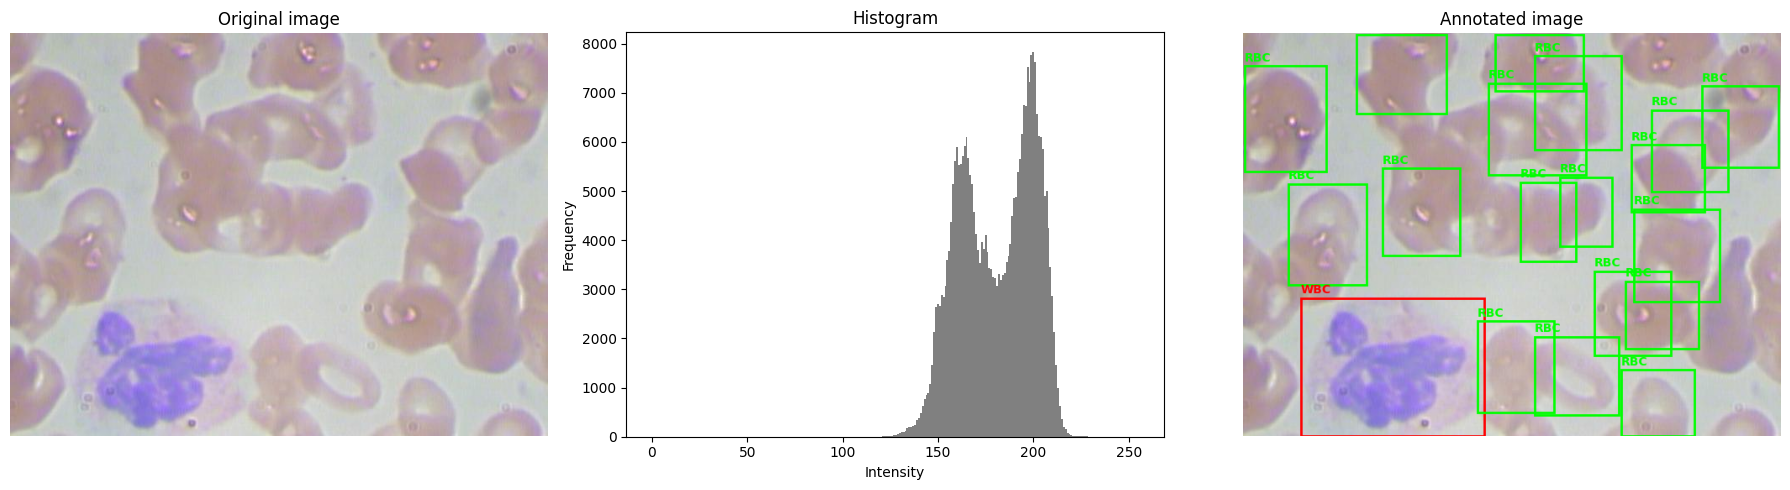

RBC: 18, WBC: 1


In [26]:
import matplotlib.patches as patches
import io

def get_image(image_path):
    image = cv2.imread(image_path)
    if image is None:
        raise ValueError("Image not found")

    return image

def get_histogram(image):
    if image.ndim == 3:
        gray_image = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)
    else:
        gray_image = image

    hist = cv2.calcHist([gray_image], [0], None, [256], [0, 256])
    return hist.flatten()

def get_annotations_path(image_path):
    base_dir = os.path.dirname(os.path.dirname(image_path)) # Go up to split folder
    filename = os.path.basename(image_path)
    
    # Path logic: image.jpeg -> image.jpeg.json
    annotation_path = os.path.join(base_dir, 'ann', filename + ".json")
    if not os.path.exists(annotation_path):
        raise FileNotFoundError(f"Annotation file not found at: {annotation_path}")
    return annotation_path

def get_annotations(annotations_path):
    """Load and return the JSON annotation data as a dictionary."""
    with open(annotations_path, 'r', encoding='utf-8') as f:
        data = json.load(f)
    return data

def get_annotated_image(image, annotations):
    """
    Returns a new image with annotations burned in.
    """
    fig, ax = plt.subplots(figsize=(image.shape[1]/100, image.shape[0]/100), dpi=100)
    
    ax.imshow(cv2.cvtColor(image, cv2.COLOR_BGR2RGB))
    ax.axis('off')
    fig.subplots_adjust(left=0, right=1, top=1, bottom=0)

    for obj in annotations.get('objects', []):
        if obj['geometryType'] == 'rectangle':
            p1, p2 = obj['points']['exterior']
            x, y = p1[0], p1[1]
            w, h = p2[0] - p1[0], p2[1] - p1[1]
            
            label = obj['classTitle']
            
            if label == 'WBC': color = 'red'
            elif label == 'RBC': color = 'lime'
            elif label == 'Platelets': color = 'cyan' 
            else: color = 'yellow' 
            
            rect = patches.Rectangle((x, y), w, h, linewidth=2, edgecolor=color, fill=False)
            ax.add_patch(rect)
            ax.text(x, y - 5, label, color=color, fontsize=10, fontweight='bold')

    # Convert plot to a numpy array
    io_buf = io.BytesIO()
    fig.savefig(io_buf, format='raw', dpi=100)
    io_buf.seek(0)
    img_arr = np.frombuffer(io_buf.getvalue(), dtype=np.uint8)
    img_arr = img_arr.reshape(int(fig.bbox.bounds[3]), int(fig.bbox.bounds[2]), -1)
    
    # Drop Alpha channel if present
    if img_arr.shape[2] == 4:
        img_arr = img_arr[:, :, :3]

    plt.close(fig)

    return cv2.cvtColor(img_arr, cv2.COLOR_RGB2BGR)

def markers_to_detections(markers, wbc_mask, padding=10):
    """
    Converts segmentation markers into bounding boxes with optional padding.
    """
    detections = []
    h_img, w_img = markers.shape[:2] # Image dimensions for boundary checks

    # Helper function to safely expand a box
    def get_padded_box(x, y, w, h, pad, max_w, max_h):
        new_x = max(0, x - pad)
        new_y = max(0, y - pad)
        
        # Increase width and height by 2*pad (to expand right and down too)
        new_w = min(max_w - new_x, w + (2 * pad))
        new_h = min(max_h - new_y, h + (2 * pad))
        
        return [int(new_x), int(new_y), int(new_w), int(new_h)]

    # RBC Detections (from Markers)
    labels = np.unique(markers)
    for label in labels:
        if label <= 1: continue  # Skip background (1) and unknown (0)
        
        # Create a temporary mask for this specific cell
        cell_mask = np.zeros(markers.shape, dtype="uint8")
        cell_mask[markers == label] = 255
        
        # Find bounding rect
        cnts, _ = cv2.findContours(cell_mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
        if cnts:
            x, y, w, h = cv2.boundingRect(cnts[0])
            
            padded_box = get_padded_box(x, y, w, h, padding, w_img, h_img)
            
            detections.append({
                'classTitle': 'RBC',
                'box': padded_box
            })

    # WBC Detections (from Mask)
    cnts_wbc, _ = cv2.findContours(wbc_mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    for c in cnts_wbc:
        x, y, w, h = cv2.boundingRect(c)
        # WBCs usually need more padding
        wbc_pad = padding + 10 
        padded_box = get_padded_box(x, y, w, h, wbc_pad, w_img, h_img)
        
        detections.append({
            'classTitle': 'WBC',
            'box': padded_box
        })
    return detections

def visualize_detections(image, detections):
    fig, ax = plt.subplots(figsize=(image.shape[1]/100, image.shape[0]/100), dpi=100)
    ax.imshow(cv2.cvtColor(image, cv2.COLOR_BGR2RGB))
    ax.axis('off')
    fig.subplots_adjust(left=0, right=1, top=1, bottom=0)

    for obj in detections:
        label = obj['classTitle']
        x, y, w, h = obj['box']
        
        if label == 'WBC': color = 'red'
        elif label == 'RBC': color = 'lime'
        rect = patches.Rectangle((x, y), w, h, linewidth=2, edgecolor=color, fill=False)
        ax.add_patch(rect)
        ax.text(x, y - 5, label, color=color, fontsize=10, fontweight='bold')

    io_buf = io.BytesIO()
    fig.savefig(io_buf, format='raw', dpi=100)
    io_buf.seek(0)
    img_arr = np.frombuffer(io_buf.getvalue(), dtype=np.uint8)
    img_arr = img_arr.reshape(int(fig.bbox.bounds[3]), int(fig.bbox.bounds[2]), -1)
    if img_arr.shape[2] == 4: img_arr = img_arr[:, :, :3]
    plt.close(fig)
    return cv2.cvtColor(img_arr, cv2.COLOR_RGB2BGR)
    
def plot_data(data, titles=None):
    if not isinstance(data, list):
        data = [data]
    
    if titles is None or len(titles) != len(data):
        titles = [None] * len(data)
        
    num_items = len(data)
    fig, axes = plt.subplots(1, num_items, figsize=(6 * num_items, 5))
    
    if num_items == 1:
        axes = [axes]

    for ax, item, title in zip(axes, data, titles):
        
        if item.ndim == 3:
            item_rgb = cv2.cvtColor(item, cv2.COLOR_BGR2RGB)
            ax.imshow(item_rgb)
            ax.axis('off')
            default_title = "Image"
            
        elif item.ndim == 2:
            ax.imshow(item, cmap='gray')
            ax.axis('off')
            default_title = "Mask/Grayscale"
            
        elif item.ndim == 1:
            ax.bar(range(len(item)), item, width=1, color='gray', edgecolor='none')
            ax.set_xlabel("Intensity")
            ax.set_ylabel("Frequency")
            default_title = "Histogram"

        if title:
            ax.set_title(title)
        else:
            ax.set_title(default_title)

    plt.tight_layout()
    plt.show()
    
def get_ground_truth(annotations):

    try:
        counts = {'WBC': 0, 'RBC': 0}
        if 'objects' in annotations:
            for obj in annotations['objects']:
                label = obj.get('classTitle')
                if label in counts:
                    counts[label] += 1
        
        return counts['WBC'], counts['RBC']
    except Exception as e:
        raise ValueError(f"Failed to parse ground truth data: {e}")

def compute_iou(boxA, boxB):
    # box format: [x1, y1, x2, y2]
    xA = max(boxA[0], boxB[0])
    yA = max(boxA[1], boxB[1])
    xB = min(boxA[2], boxB[2])
    yB = min(boxA[3], boxB[3])
    
    interArea = max(0, xB - xA) * max(0, yB - yA)
    boxAArea = (boxA[2] - boxA[0]) * (boxA[3] - boxA[1])
    boxBArea = (boxB[2] - boxB[0]) * (boxB[3] - boxB[1])
    
    iou = interArea / float(boxAArea + boxBArea - interArea + 1e-6)
    return iou

def compute_image_iou(gt_boxes, pred_boxes):
    if len(gt_boxes) == 0:
        return 1.0 if len(pred_boxes) == 0 else 0.0
    if len(pred_boxes) == 0:
        return 0.0

    ious = []
    for gt_box in gt_boxes:
        best_iou = 0
        for pred_box in pred_boxes:
            iou = compute_iou(gt_box, pred_box)
            if iou > best_iou:
                best_iou = iou
        ious.append(best_iou)
    
    return np.mean(ious)

# sample_image_path = glob.glob(os.path.join(DIRS['test']['img'], '*.jpeg'))[0]
sample_image_path = 'bccd-blood-cell-count-and-detection-dataset/train/img/BloodImage_00001.jpeg'
sample_image = get_image(sample_image_path)
sample_histogram = get_histogram(sample_image)
sample_annotations = get_annotations(get_annotations_path(sample_image_path))
sample_annotated_image = get_annotated_image(sample_image, sample_annotations)
plot_data([sample_image, sample_histogram, sample_annotated_image], titles=["Original image", "Histogram", "Annotated image"])
sample_wbc, sample_rbc = get_ground_truth(sample_annotations)
print(f"RBC: {sample_rbc}, WBC: {sample_wbc}")

# Classical Image Processing Pipeline

This section implements a pipeline leveraging classical image processing techniques, mainly using `opencv` and `numpy`.

**Overview:**
1. **WBCs:** The image undergoes contrast enhancement, followed by color masking to isolate the regions of interest. This facilitates the specific detection and enumeration of White Blood Cells.
1. **RBCs:** The Green channel is enhanced using CLAHE and Gaussian blurring. After distinguishing the foreground from the background, the Watershed algorithm is applied to segment individual Red Blood Cells.

## White Blood Cells

### Preprocessing
To optimize the detection of White Blood Cells (WBCs), the input images undergo a preprocessing stage. This phase primarily utilizes CLAHE (Contrast Limited Adaptive Histogram Equalization) and Gaussian blurring to suppress noise.

To enhance local contrast, CLAHE is applied specifically to the Lightness (L) channel of the [LAB](https://opencv.org/blog/color-spaces-in-opencv/#h-lab-lightness-a-channel-b-channel-color-space) representation).
The processed image demonstrates increased contrast and a broader histogram distribution, confirming the effectiveness of the equalization.

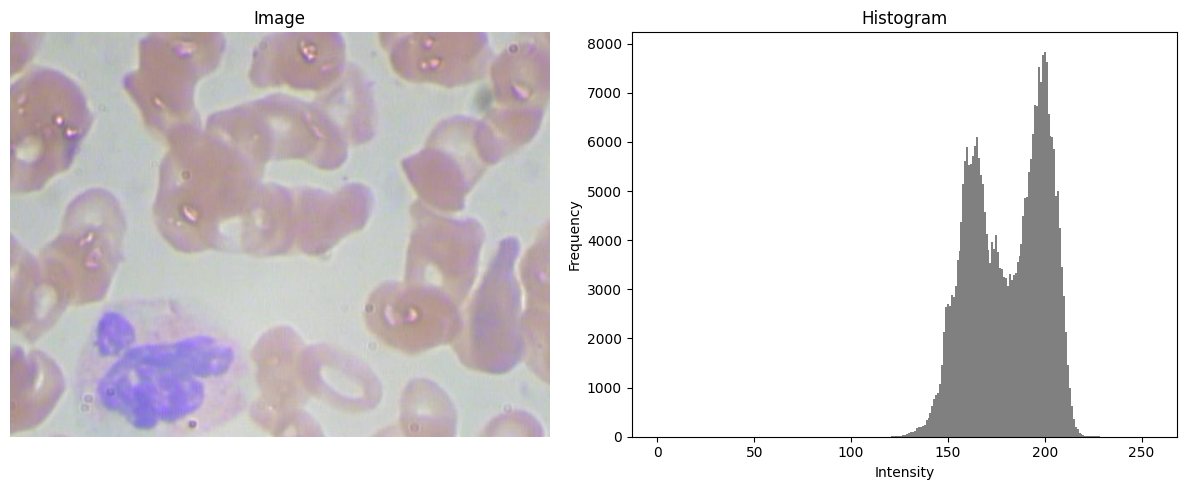

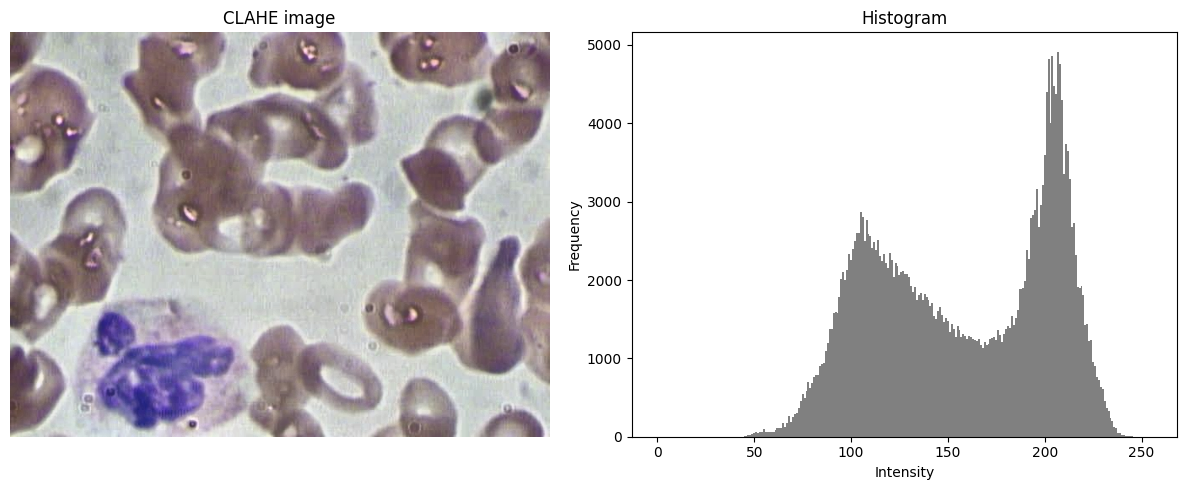

In [5]:
def apply_CLAHE(image):
    """
    Applies Contrast Limited Adaptive Histogram Equalization (CLAHE) 
    to the Lightness (L) channel of an image.
    """
    
    clahe = cv2.createCLAHE(clipLimit=3.0, tileGridSize=(8, 8))
    lab = cv2.cvtColor(image, cv2.COLOR_BGR2LAB)
    l, a, b = cv2.split(lab)
    l_clahe = clahe.apply(l)
    lab_merged = cv2.merge((l_clahe, a, b))
    clahe_image = cv2.cvtColor(lab_merged, cv2.COLOR_LAB2BGR)
    
    return clahe_image

sample_clahe_image = apply_CLAHE(sample_image)
sample_histogram = get_histogram(sample_image)
sample_clahe_histogram = get_histogram(sample_clahe_image)

plot_data([sample_image, sample_histogram], titles=["Image", "Histogram"])
plot_data([sample_clahe_image, sample_clahe_histogram], titles=["CLAHE image", "Histogram"])

Then, Gaussian blur is used to smoothen out the histogram of the processed image, allowing for better detection later on.

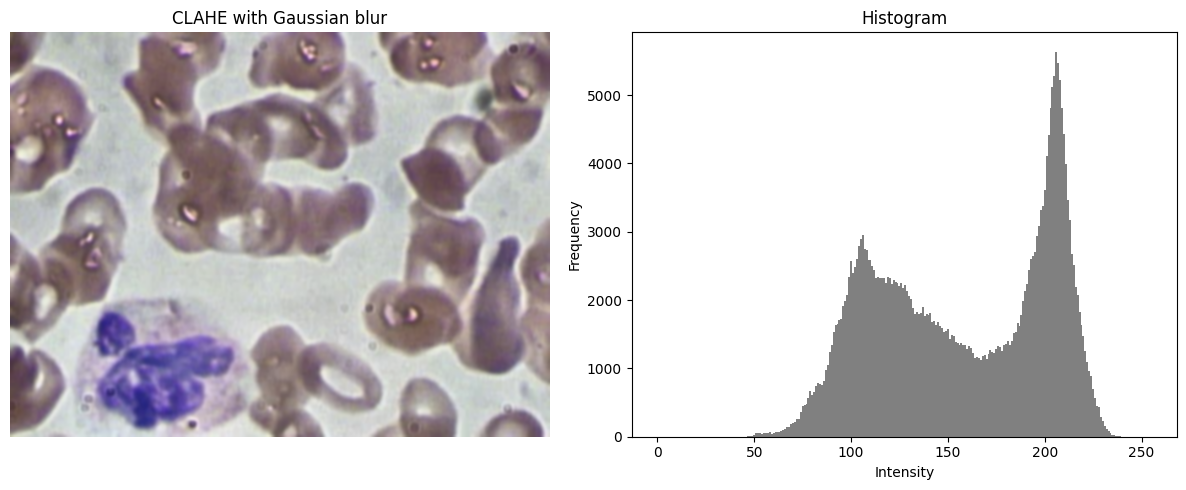

In [6]:
def apply_gaussian_blur(image, kernel_size=(7, 7)):
   return cv2.GaussianBlur(image, kernel_size, 0)

sample_blurred_image = apply_gaussian_blur(sample_clahe_image)
sample_merged_histogram = get_histogram(sample_blurred_image)
sample_clahe_histogram = get_histogram(sample_clahe_image)
plot_data([sample_blurred_image, sample_merged_histogram], titles=["CLAHE with Gaussian blur", "Histogram"])

### Detection
Now that the preprocessing has been applied to the image, the pipeline proceeds to the segmentation and enumeration of White Blood Cells (WBCs).

The [HSV](https://opencv.org/blog/color-spaces-in-opencv/#h-hsv-hue-saturation-value-color-space) is utilized to isolate White Blood Cells (WBCs) by exploiting their distinct purple coloration compared to other cellular components. 
A binary mask is generated using specific color thresholds (obtained using [this utility Python script](https://github.com/di-bon/hsv_picker)) to effectively filter out all the colors that are not purple.

Visualization Note: In the debug plots below, the "HSV Image" is rendered by passing the raw HSV data directly to the plotting function, which expects RGB input. While this results in a false-color representation (where Hue is interpreted as Red, Saturation as Green, Value as Blue), the underlying image data remains identical. This visualization serves only to confirm the successful transformation of the pixel data into the HSV coordinate system. Also, by using this representation we can easily see which regions the mask is extracting form the image.

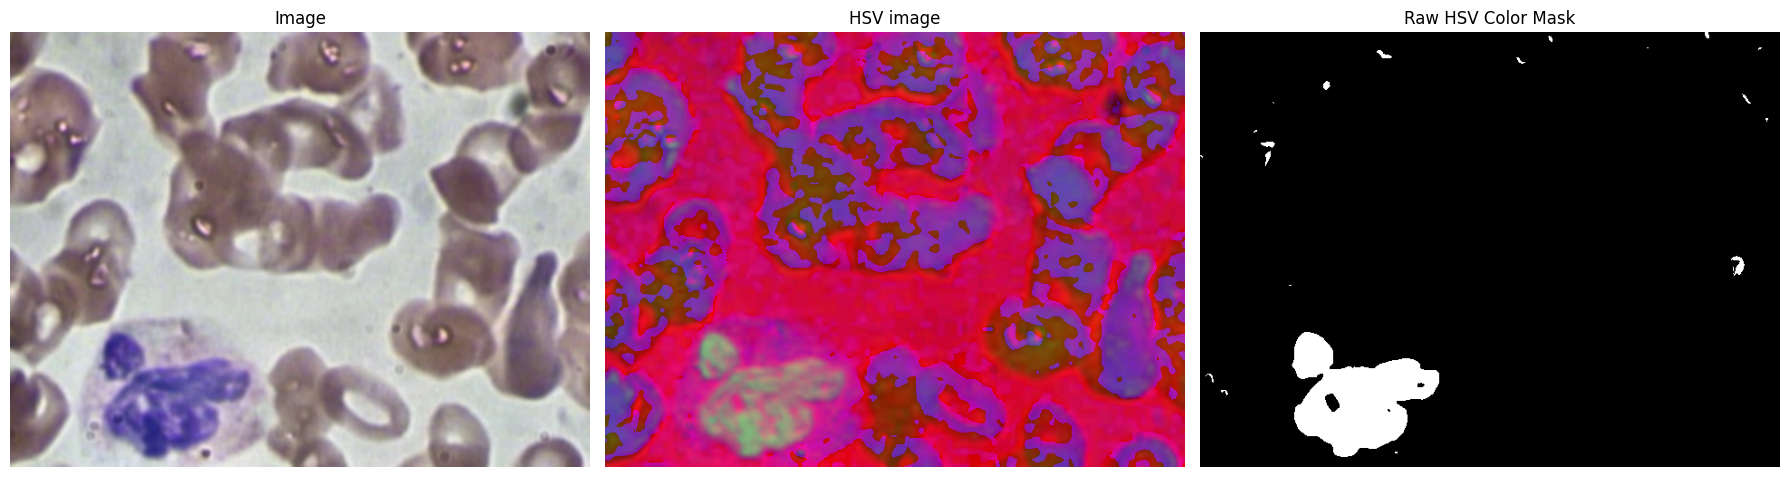

In [ ]:
def get_hsv_mask(hsv_image, lower_thresh, upper_thresh, debug=False):
    color_mask = cv2.inRange(hsv_image, lower_thresh, upper_thresh)

    if debug:
        bgr_image = cv2.cvtColor(hsv_image, cv2.COLOR_HSV2BGR)
        plot_data([bgr_image, hsv_image, color_mask], titles=["Image", "HSV image","Raw HSV Color Mask"])

    return color_mask

sample_hsv_image = cv2.cvtColor(sample_blurred_image, cv2.COLOR_BGR2HSV)

sample_lower_purple = np.array([79, 77, 109])
sample_upper_purple = np.array([151, 212, 212])

sample_color_mask = get_hsv_mask(sample_hsv_image, sample_lower_purple, sample_upper_purple, debug=True)

Once the binary mask is generated, some [morphological operations](https://docs.opencv.org/4.x/d9/d61/tutorial_py_morphological_ops.html) are applied to refine it, reducing noise and ensuring structural consistency.

With the opening step, noise is removed by first applying an erosion step and then a dilation step. This filters out all the small regions (likely noise) of the mask.\
With the closing step, the opposite operation is performed, i.e. a dilation step folowed by an erosion one. This allows to fill the holes of the mask.

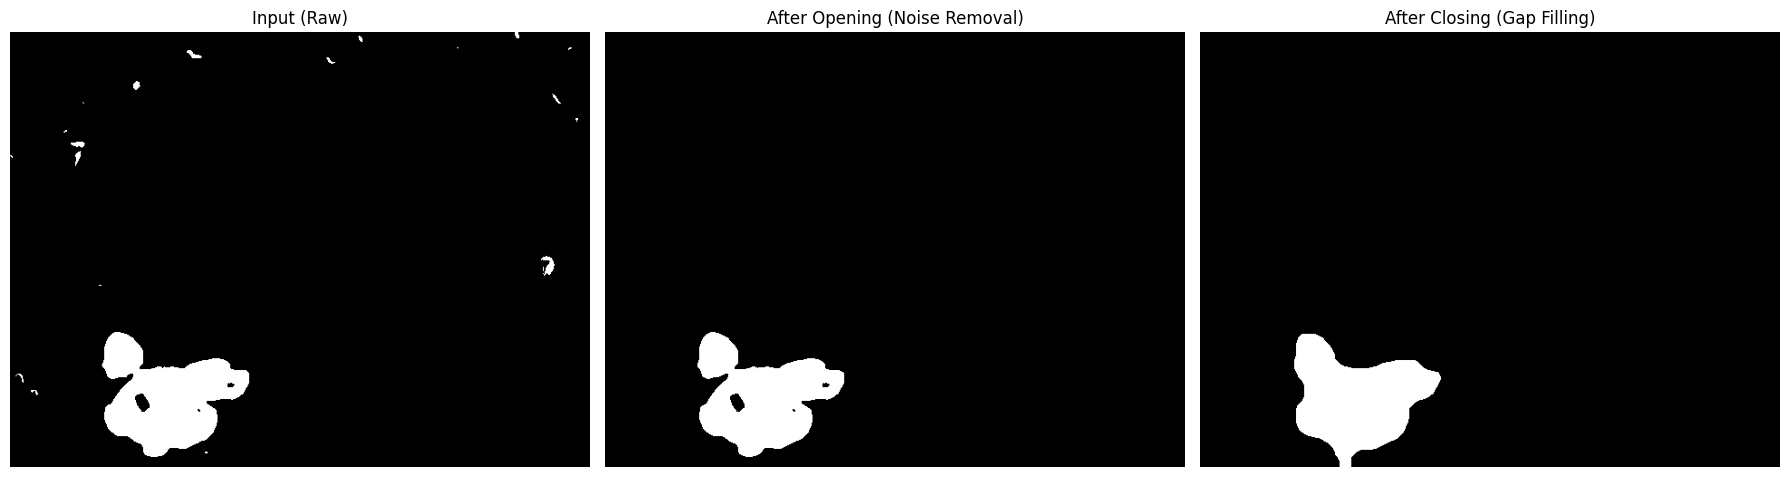

In [8]:
def clean_wbc_morphology(mask, debug=False):
    """
    Applies morphological operations (Open + Close) to clean the WBC mask.
    WBCs need strong 'Closing' to fill gaps in the nucleus.
    """

    kernel_open = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (5, 5))
    mask_open = cv2.morphologyEx(mask, cv2.MORPH_OPEN, kernel_open, iterations=2)

    kernel_close = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (20, 20))
    mask_cleaned = cv2.morphologyEx(mask_open, cv2.MORPH_CLOSE, kernel_close, iterations=2)
    
    if debug:
        plot_data(
            [mask, mask_open, mask_cleaned], 
            titles=["Input (Raw)", "After Opening (Noise Removal)", "After Closing (Gap Filling)"]
        )

    return mask_cleaned

sample_wbc_morph = clean_wbc_morphology(sample_color_mask, debug=True)

Finally, domain knowledge regarding cell size is utilized to refine the detection results. Connected components within the mask that fall below a specific area threshold are identified as noise and discarded, ensuring that only valid White Blood Cell candidates remain.

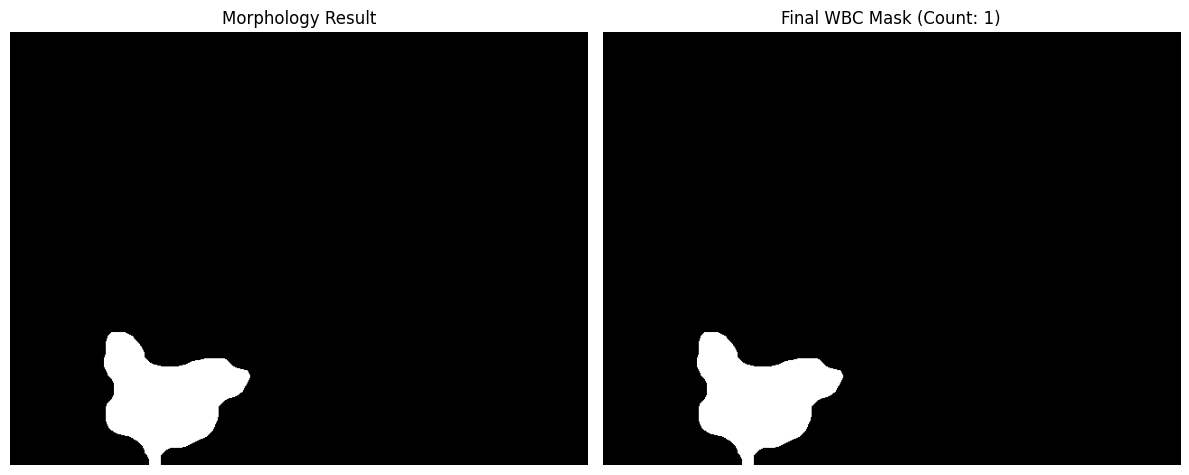

WBCs Detected: 1


In [9]:
def filter_wbc_by_size(mask, min_area=1500, debug=False):
    """
    Filters connected components based on area. 
    Keeps only large objects (WBCs).
    """
    num_labels, labels, stats, centroids = cv2.connectedComponentsWithStats(mask, connectivity=8)

    final_mask = np.zeros_like(mask)
    count = 0

    for i in range(1, num_labels):
        area = stats[i, cv2.CC_STAT_AREA]
        
        if area > min_area:
            final_mask[labels == i] = 255
            count += 1
            
    if debug:
        plot_data([mask, final_mask], titles=["Morphology Result", f"Final WBC Mask (Count: {count})"])

    return final_mask, count

sample_final_wbc_mask, sample_wbc_count = filter_wbc_by_size(sample_wbc_morph, min_area=1500, debug=True)
print(f"WBCs Detected: {sample_wbc_count}")

The processing steps described above are consolidated into a single function that detect and count the WBCs. 

WBC count: 1


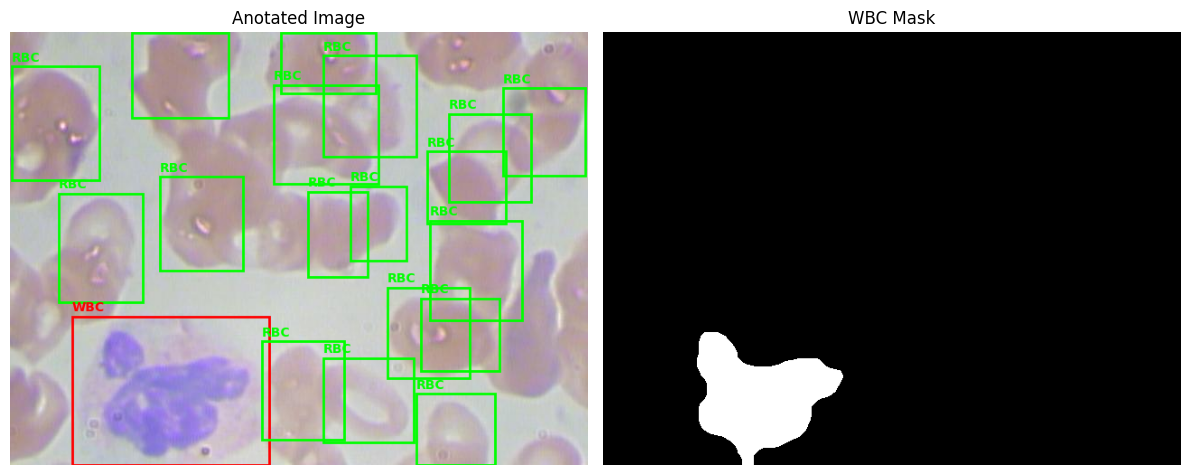

In [10]:
def get_wbc_mask(hsv_image, lower_thresh, upper_thresh, debug=False):
    raw_mask = get_hsv_mask(hsv_image, lower_thresh, upper_thresh, debug=debug)
    
    morph_mask = clean_wbc_morphology(raw_mask, debug=debug)
    
    final_mask, count = filter_wbc_by_size(morph_mask, min_area=1500, debug=debug)
    
    return final_mask, count

sample_hsv_image = cv2.cvtColor(sample_blurred_image, cv2.COLOR_BGR2HSV)

sample_lower_purple = np.array([79, 77, 109])
sample_upper_purple = np.array([151, 212, 212])

sample_wbc_mask, sample_wbc_count = get_wbc_mask(sample_hsv_image, sample_lower_purple, sample_upper_purple, debug=False)

print(f'WBC count: {sample_wbc_count}')
titles = ["Anotated Image", "WBC Mask"]
plot_data([sample_annotated_image, sample_wbc_mask], titles=titles)


## Red Blood Cells

### Preprocessing
For RBCs, a distinct preprocessing approach is adopted. The process resumes from the original BGR image.
Contrast enhancement (CLAHE) is still applied, but specifically to the Green (G) channel of the BGR color space. Since red objects appear darkest in the green spectral band, this channel provides the optimal contrast for distinguishing RBCs from the background.

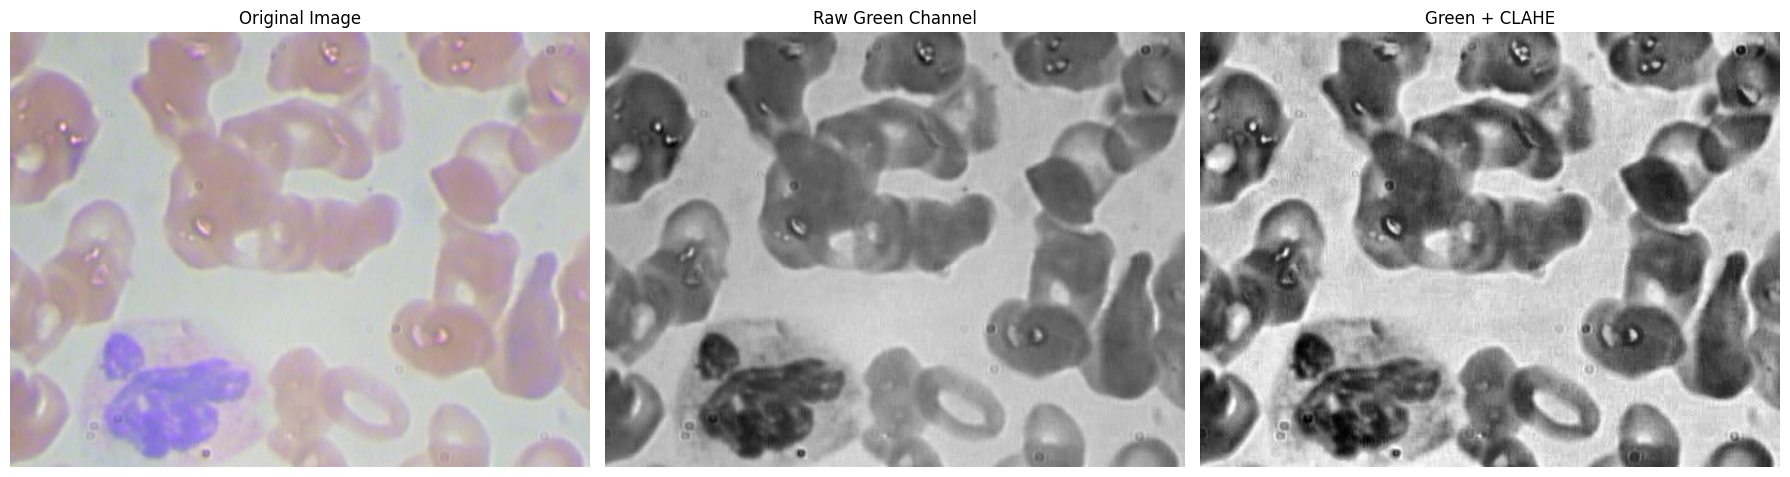

In [11]:
def rbc_extract_and_clahe(image, debug=False):
    g = image[:, :, 1] 
    
    clahe = cv2.createCLAHE(clipLimit=3.0, tileGridSize=(8, 8))
    g_clahe = clahe.apply(g)

    if debug:
        plot_data([image, g, g_clahe], titles=["Original Image", "Raw Green Channel", "Green + CLAHE"])
    
    return g_clahe

sample_g_clahe = rbc_extract_and_clahe(sample_image, debug=True)

To suppress high-frequency noise, Gaussian blurring is applied to the contrast-enhanced Green channel.

The impact of this smoothing operation is visualized by comparing the histograms of the CLAHE-processed channel before and after blurring, demonstrating a more uniform intensity distribution.

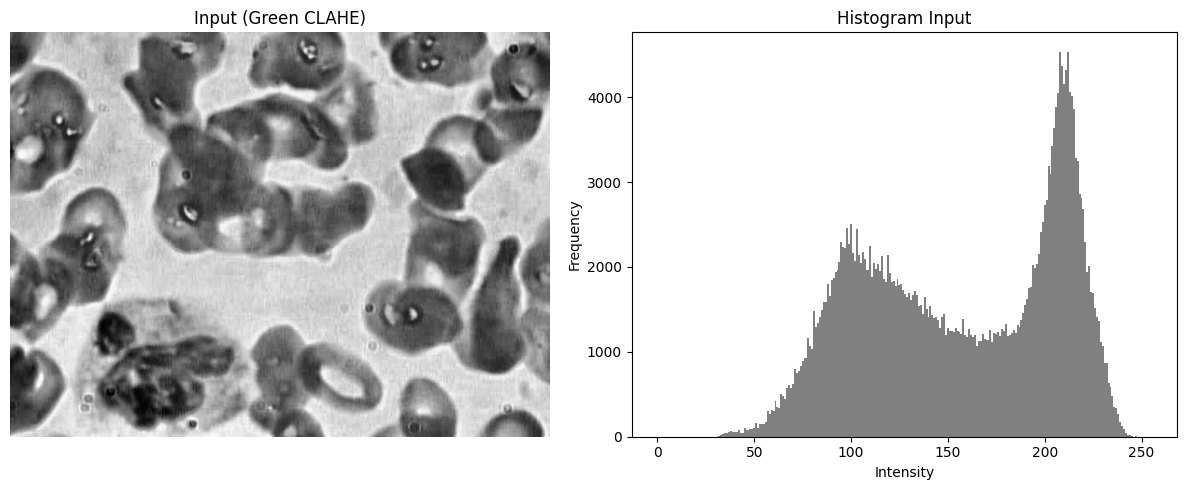

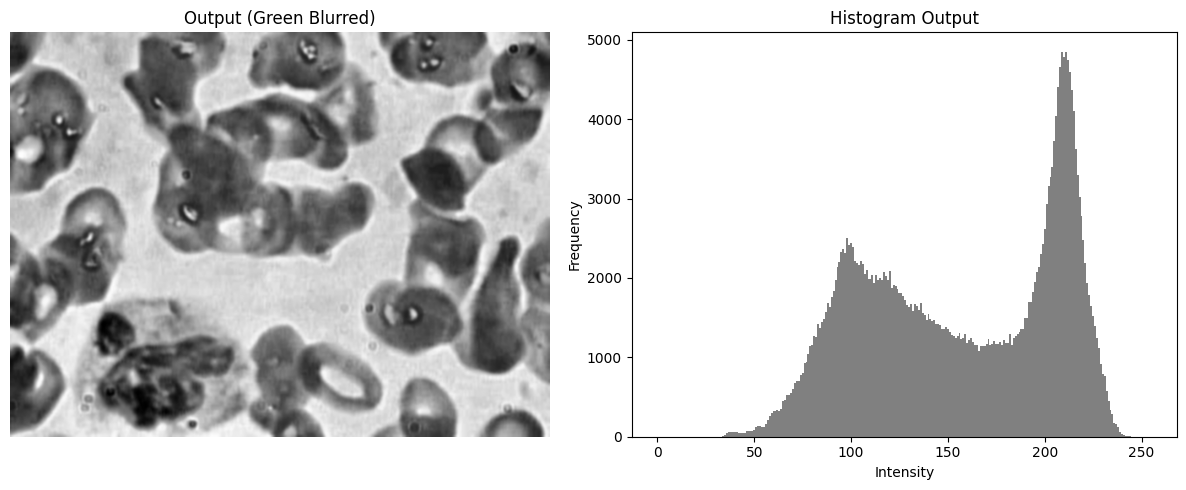

In [12]:
def rbc_blurring_phase(single_channel_image, debug=False):
    g_blurred = apply_gaussian_blur(single_channel_image, (5, 5))
    
    if debug:
        hist_input = get_histogram(single_channel_image)
        
        hist_output = get_histogram(g_blurred)
        
        plot_data(
            [single_channel_image, hist_input], 
            titles=["Input (Green CLAHE)", "Histogram Input"]
        )
        plot_data(
            [g_blurred, hist_output], 
            titles=["Output (Green Blurred)", "Histogram Output"]
        )

    return g_blurred

sample_g_blurred = rbc_blurring_phase(sample_g_clahe, debug=True)

### Detection
To detect the RBCs, an adaptive thresholding algorithm is applied. This process generates a binary mask that effectively separates the cellular foreground from the background.

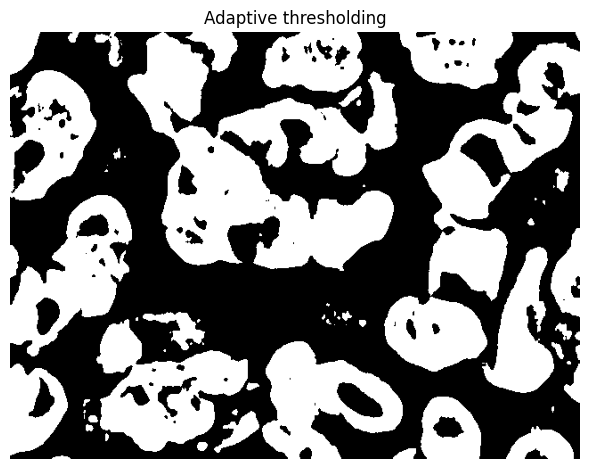

In [13]:
def rbc_apply_thresholding(g_blurred, debug=False):
    thresh = cv2.adaptiveThreshold(
        g_blurred, 
        255, 
        cv2.ADAPTIVE_THRESH_GAUSSIAN_C, 
        cv2.THRESH_BINARY_INV, 
        blockSize=201, 
        C=2
    )

    if debug:
        plot_data([thresh], titles=["Adaptive thresholding"])

    return thresh

sample_thresh = rbc_apply_thresholding(sample_g_blurred, debug=True)

Then, to eliminate artifacts frequently present near White Blood Cells, the WBC mask is moderately dilated and subtracted from the RBC mask. This ensures that the RBC segmentation remains uncontaminated by WBC boundaries.

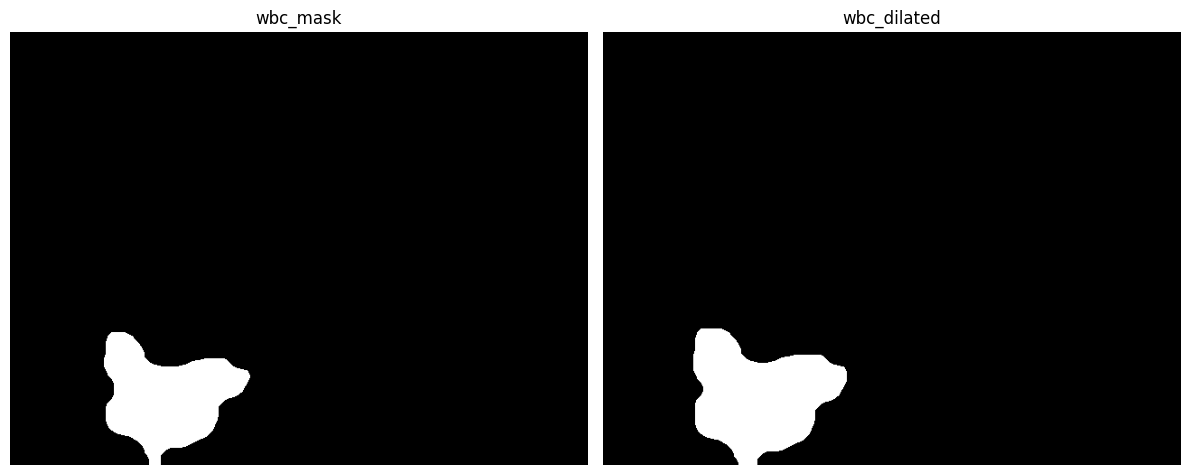

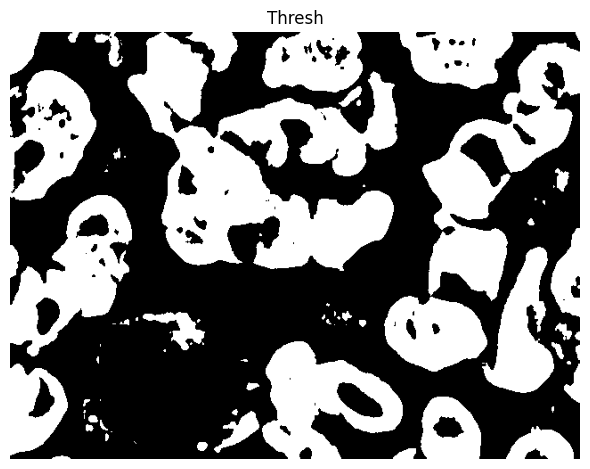

In [14]:
def rbc_remove_wbc_mask(wbc_mask, thresh, debug=False):
    wbc_dilated = cv2.dilate(wbc_mask, np.ones((5,5), np.uint8), iterations=2)
    thresh[wbc_dilated > 0] = 0

    if debug:
        plot_data([wbc_mask, wbc_dilated], titles=["wbc_mask", "wbc_dilated"])
        plot_data([thresh], titles=["Thresh"])

    return thresh

sample_thresh = rbc_remove_wbc_mask(sample_wbc_mask, sample_thresh, debug=True)

Applying the same morphological strategy employed for WBCs, the mask is refined to remove noise and irregularities. The resulting binary map represents the sure background of the image.

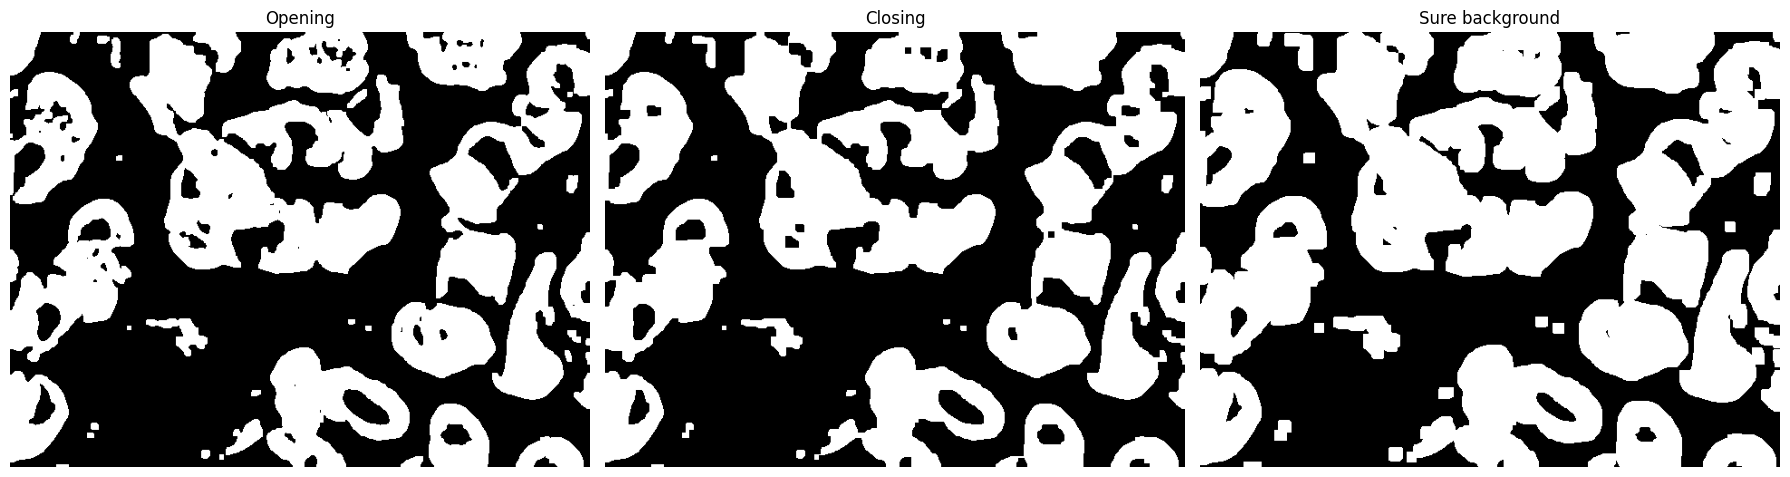

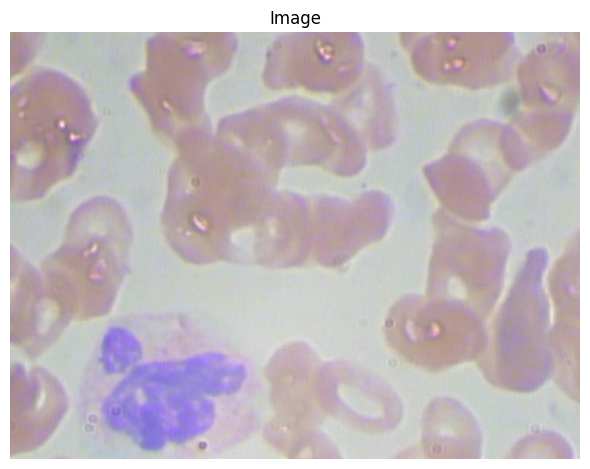

In [15]:
def rbc_get_sure_bg(thresh, debug=False):
    kernel = np.ones((3,3), np.uint8)
    opening = cv2.morphologyEx(thresh, cv2.MORPH_OPEN, kernel, iterations=2)
    closing = cv2.morphologyEx(opening, cv2.MORPH_CLOSE, kernel, iterations=3)
    sure_bg = cv2.dilate(closing, kernel, iterations=3)

    if debug:
        plot_data([opening, closing, sure_bg], titles=["Opening", "Closing", "Sure background"])
    
    return sure_bg, closing

sample_sure_bg, sample_closing = rbc_get_sure_bg(sample_thresh, debug=True)
plot_data([sample_image], titles=["Image"])

To prepare for the Watershed algorithm, two critical masks must be defined: the Sure Foreground (cell centers) and the Unknown Region (regions where it can be hard to precisely tell where the countours of the RBCs actually are). To achieve this, a Distance Dransform is used to identify the regions of the cells that are RBCs (i.e. the areas that are far away from the background). Gaussian blurring is then applied to make the watershed algorithm work better later on. 
After that, a threshold is applied to the distance map to isolate the most central regions of the cells, ensuring high confidence that these pixels belong to RBCs.
Lastly, the Unknown Region is derived by subtracting the Sure Foreground from the Sure Background.

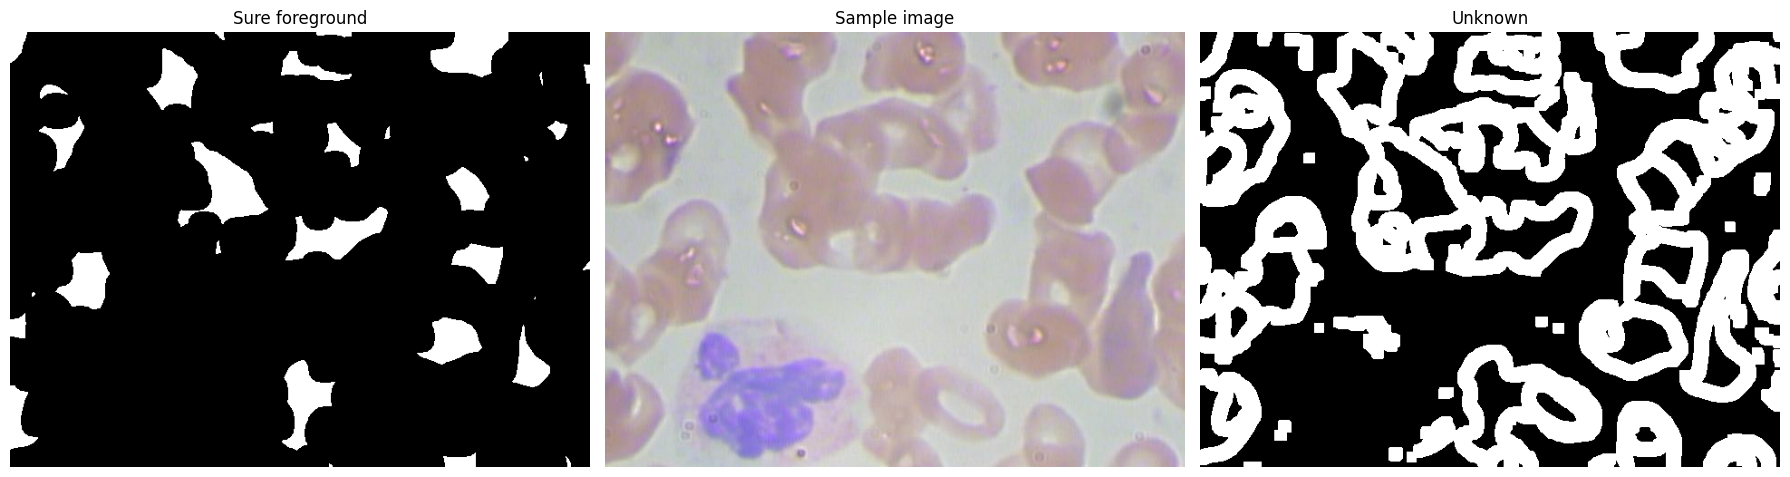

In [16]:
def rbc_get_sure_foreground(closing, sure_bg, debug=False):
    dist_transform = cv2.distanceTransform(closing, cv2.DIST_L2, 5)
    dist_transform = cv2.GaussianBlur(dist_transform, (3, 3), 0)
    ret, sure_fg = cv2.threshold(dist_transform, 0.35 * dist_transform.max(), 255, 0)
    sure_fg = np.uint8(sure_fg)
    unknown = cv2.subtract(sure_bg, sure_fg)
    
    if debug:
        plot_data([sure_fg, unknown], titles=["Sure foreground", "Unknown"])
    
    return sure_fg, unknown

sample_sure_fg, sample_unknown = rbc_get_sure_foreground(sample_closing, sample_sure_bg, debug=False)
plot_data([sample_sure_fg, sample_image, sample_unknown], titles=["Sure foreground", "Sample image", "Unknown"])

With the Sure Soreground and Unknown Region masks defined, the Watershed algorithm is applied to execute the final segmentation of Red Blood Cells (RBCs).
Conceptually, this algorithm treats the image as a topographic surface. The Sure Foreground regions serve as markers (seeds) from which a simulated flooding process initiates. The "water" expands from these markers into the Unknown Regions until it converges with expanding regions from adjacent markers. These convergence points form watershed lines, which effectively delineate the boundaries between overlapping cells.

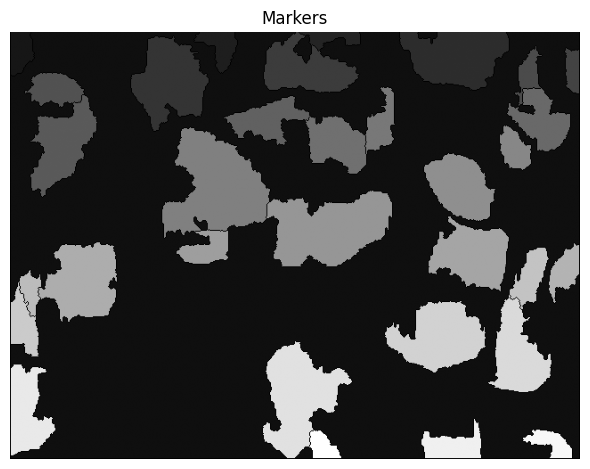

In [17]:
def rbc_apply_watershed(sure_fg, unknown, image, debug=False):
    ret, markers = cv2.connectedComponents(sure_fg)
    markers = markers + 1
    markers[unknown == 255] = 0
    
    markers = cv2.watershed(image, markers)

    if debug:
        plot_data([markers], titles=["Markers"])

    return markers

sample_markers = rbc_apply_watershed(sample_sure_fg, sample_unknown, sample_image, debug=True)

To eliminate residual noise, a size constraint is applied to discard regions that are too small to correspond to a valid Red Blood Cell. The remaining connected components are subsequently enumerated to derive the final cell count.

DEBUG: Using Fixed RBC Area: 6000px. (Min: 2400.0, Clump: 10800.0)
DEBUG: Found 34 unique labels in markers.


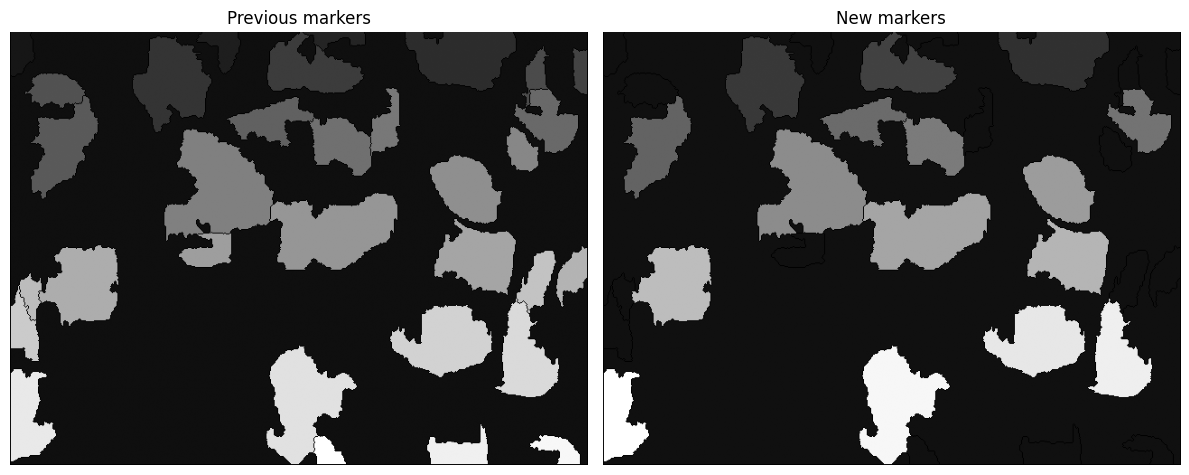

In [18]:
def rbc_size_filtering(typical_rbc_area, markers, debug=False):
    min_thresh = typical_rbc_area * 0.4 # changed to 0.4 from 0.2
    clump_thresh = typical_rbc_area * 1.8

    if debug:
        print(f"DEBUG: Using Fixed RBC Area: {typical_rbc_area}px. (Min: {min_thresh}, Clump: {clump_thresh})")
        
    final_count = 0
    new_markers = markers.copy()
    
    labels = np.unique(markers)

    if debug:
        print(f"DEBUG: Found {len(labels)} unique labels in markers.") 
    
    for label in labels:
        if label <= 1: continue
        
        area = np.sum(markers == label)
        
        if area < min_thresh:
            new_markers[markers == label] = 1 
        elif area > clump_thresh:
            estimated_cells = int(round(area / typical_rbc_area))
            print(f"   -> Found Clump (Area {area}). Estimated as {estimated_cells} cells.")
            final_count += estimated_cells
        else:
            final_count += 1

    if debug:
        plot_data([markers, new_markers], titles=["Previous markers", "New markers"])
    
    return new_markers, final_count

sample_new_markers, sample_count = rbc_size_filtering(6000, sample_markers, debug=True)

Here is a funciton that encapsulates the entire RBC logic to ensure modularity.

RBC Count detected: 16


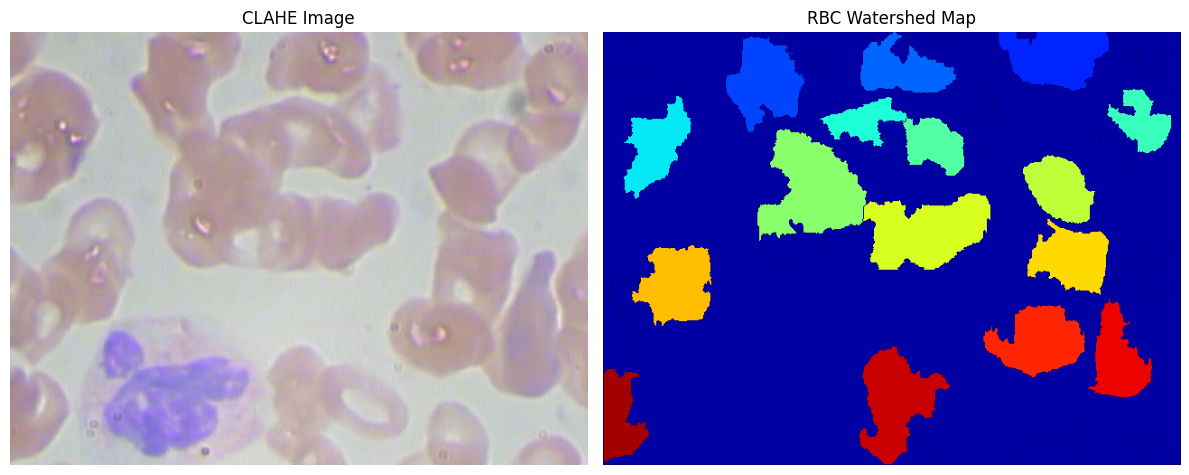

In [19]:
def get_rbc_watershed(image, wbc_mask, typical_rbc_area=6000):
    g_clahe = rbc_extract_and_clahe(image, debug=False)    
    
    g_blurred = rbc_blurring_phase(g_clahe, debug=False)    
    
    thresh = rbc_apply_thresholding(g_blurred)
    
    thresh = rbc_remove_wbc_mask(wbc_mask, thresh)
    
    sure_bg, closing = rbc_get_sure_bg(thresh)
    
    sure_fg, unknown = rbc_get_sure_foreground(closing, sure_bg)

    markers = rbc_apply_watershed(sure_fg, unknown, image)

    new_markers, count = rbc_size_filtering(typical_rbc_area=typical_rbc_area, markers=markers)

    return new_markers, count
    
FIXED_AREA = 6000 
sample_markers, sample_rbc_count = get_rbc_watershed(sample_image, sample_wbc_mask, typical_rbc_area=FIXED_AREA)

sample_colored_markers = plt.cm.jet(sample_markers / (np.max(sample_markers) + 1))
sample_colored_markers = (sample_colored_markers[:, :, :3] * 255).astype(np.uint8)
sample_final_markers_bgr = cv2.cvtColor(sample_colored_markers, cv2.COLOR_RGB2BGR)

print(f"RBC Count detected: {sample_rbc_count}")
plot_data([sample_image, sample_final_markers_bgr], titles=["CLAHE Image", "RBC Watershed Map"])

## Full pipeline
Below, the full pipeline is defined inside a wrapper class, so all the steps described above can be easily applied to all the images in the dataset

✅ Image found: bccd-blood-cell-count-and-detection-dataset/train/img/BloodImage_00001.jpeg
📊 Ground Truth -> WBC: 1, RBC: 18, Platelets: 0


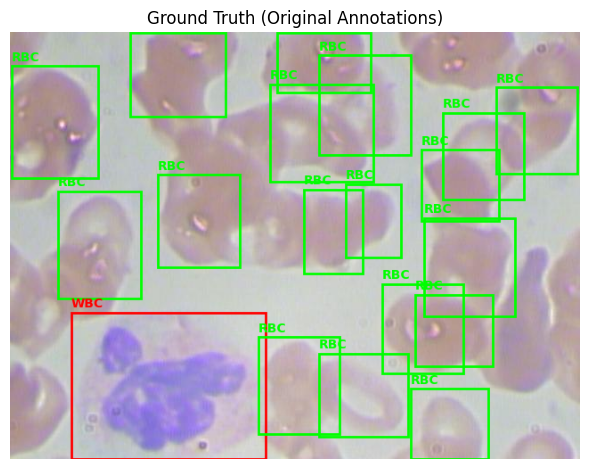


🚀 Running Detection Pipeline...
--- Pipeline Result: WBC=1, RBC=16---


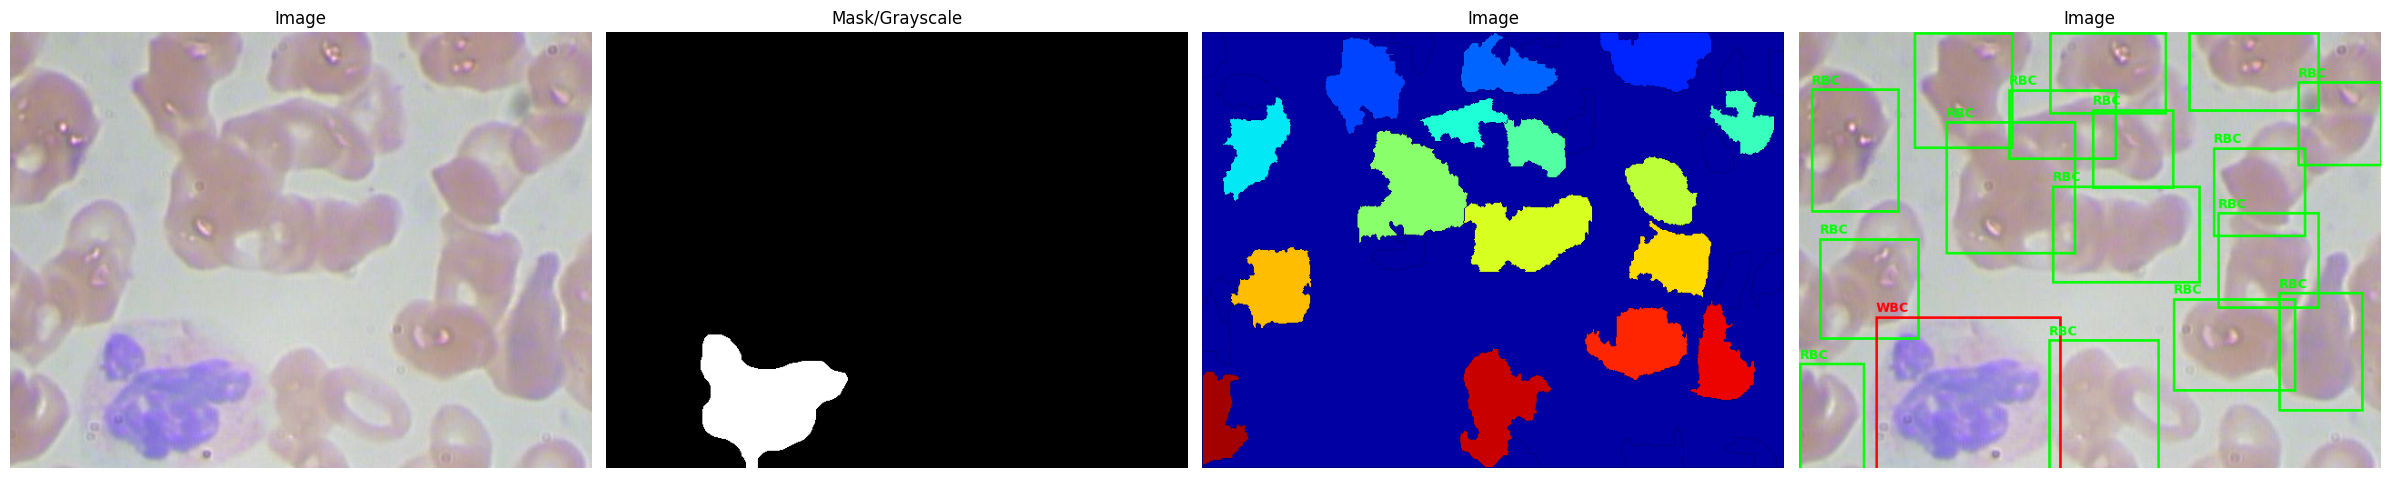

In [ ]:
class ClassicalCellDetector:
    def __init__(self):
        self.lower_purple = np.array([79, 77, 109])
        self.upper_purple = np.array([151, 212, 212])
        self.typical_rbc_area = 6000

    def detect_wbc(self, image):
        gaussian_blurred = apply_gaussian_blur(image)
        hsv_image = cv2.cvtColor(gaussian_blurred, cv2.COLOR_BGR2HSV)
        mask, count = get_wbc_mask(hsv_image, self.lower_purple, self.upper_purple)
        return mask, count

    def detect_rbc(self, image, wbc_mask):
        rbc_markers, rbc_count = get_rbc_watershed(image, wbc_mask, typical_rbc_area=self.typical_rbc_area)
        return rbc_markers, rbc_count
    
    def run_pipeline(self, image, visualize=False):
        clahe_image = apply_CLAHE(image)
        
        wbc_mask, wbc_count = self.detect_wbc(clahe_image.copy())

        rbc_markers, rbc_count = self.detect_rbc(image.copy(), wbc_mask)
        
        # --- Visualization ---
        detections = markers_to_detections(rbc_markers, wbc_mask)
        vis_boxes = visualize_detections(image.copy(), detections)
        
        vis_regions = image.copy()
        
        # Red = WBC
        cnts_wbc, _ = cv2.findContours(wbc_mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
        cv2.drawContours(vis_regions, cnts_wbc, -1, (0, 0, 255), 2)
        
        # Green = RBC
        labels = np.unique(rbc_markers)
        for label in labels:
            if label <= 1: continue
            cell_mask = np.zeros(rbc_markers.shape, dtype="uint8")
            cell_mask[rbc_markers == label] = 255
            cnts_cell, _ = cv2.findContours(cell_mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
            cv2.drawContours(vis_regions, cnts_cell, -1, (0, 255, 0), 1)

        if visualize:
            print(f"--- Pipeline Result: WBC={wbc_count}, RBC={rbc_count}---")
            
            marker_colored = plt.cm.jet(rbc_markers / (np.max(rbc_markers) + 1)) 
            marker_colored = (marker_colored[:, :, :3] * 255).astype(np.uint8)   
            marker_bgr = cv2.cvtColor(marker_colored, cv2.COLOR_RGB2BGR)         

            plot_data(
                [image, wbc_mask, marker_bgr, vis_boxes], 
                titles=[
                    "Original", 
                    "WBC Mask", 
                    "Platelet Mask", 
                    "RBC Markers", 
                    "Final (Boxes)"
                ]
            )

        return {
            'wbc_count': wbc_count,
            'rbc_count': rbc_count,
            'detections': detections,
            'final_vis': vis_boxes 
        }

img_path = 'bccd-blood-cell-count-and-detection-dataset/train/img/BloodImage_00001.jpeg'

if os.path.exists(img_path):
    print(f"Image found: {img_path}")
    
    detector = ClassicalCellDetector()
    
    image = get_image(img_path)
    
    try:
        ann_path = get_annotations_path(img_path)
        gt_data = get_annotations(ann_path)
        
        # Calculate GT counts
        gt_wbc = sum(1 for obj in gt_data.get('objects', []) if obj['classTitle'] == 'WBC')
        gt_rbc = sum(1 for obj in gt_data.get('objects', []) if obj['classTitle'] == 'RBC')
        gt_platelets = sum(1 for obj in gt_data.get('objects', []) if obj['classTitle'] == 'Platelets')
        
        print(f"Ground Truth -> WBC: {gt_wbc}, RBC: {gt_rbc}")
        
        annotated_img = get_annotated_image(image, gt_data)
        plot_data([annotated_img], titles=["Ground Truth (Original Annotations)"])
        
    except Exception as e:
        print(f"Could not load annotations: {e}")

    print("\nRunning Detection Pipeline...")
    result = detector.run_pipeline(image, visualize=True)
else:
    print(f"Error: File not found at {img_path}")